# Chapter 8: Learning Signal and Ignoring Noise

**Book:** *Grokking Deep Learning*  
**Author:** Andrew W. Trask

## Neural Network Regularization, Dropout, Early Stopping, and Mini-Batch Gradient Descent Using NumPy

### Tujuan Pembelajaran

Pada notebook ini, kita mempelajari beberapa konsep yang membantu proses pelatihan jaringan saraf, yaitu *mini-batch gradient descent*, *dropout*, dan *early stopping*.

Dalam pembelajaran mesin, model perlu mempelajari pola penting dari data tanpa terlalu bergantung pada kebisingan (*noise*) atau karakteristik yang hanya muncul pada data pelatihan. Model yang terlalu menyesuaikan diri dengan data pelatihan dapat mengalami *overfitting*, yaitu memiliki performa baik pada data pelatihan tetapi kurang baik pada data baru.

Kita menggunakan dataset MNIST sebagai contoh klasifikasi gambar angka tulisan tangan. Implementasi jaringan saraf dibuat menggunakan NumPy agar perhitungan utama dapat diamati secara langsung.

### 1. Memuat Dataset MNIST

MNIST berisi gambar angka tulisan tangan dari 0 sampai 9. Setiap gambar memiliki resolusi 28 × 28 piksel. Oleh karena itu, setiap gambar dapat diubah menjadi vektor dengan 784 fitur.

Data dibagi menjadi data pelatihan dan data pengujian. Data pelatihan digunakan untuk memperbarui bobot model, sedangkan data pengujian digunakan untuk mengevaluasi performa akhir. Sebagian data pelatihan juga akan dipisahkan sebagai data validasi untuk memantau proses pelatihan.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

np.random.seed(42)

# Memuat dataset
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

print("Ukuran data training:", X_train_full.shape)
print("Ukuran label training:", y_train_full.shape)
print("Ukuran data testing:", X_test.shape)
print("Ukuran label testing:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Ukuran data training: (60000, 28, 28)
Ukuran label training: (60000,)
Ukuran data testing: (10000, 28, 28)
Ukuran label testing: (10000,)


### 2. Preprocessing Data

Nilai piksel pada MNIST berada pada rentang 0–255. Nilai tersebut dinormalisasi menjadi rentang 0–1 dengan membaginya dengan 255.

Setiap gambar berukuran 28 × 28 kemudian diubah menjadi vektor satu dimensi berukuran 784. Transformasi ini diperlukan karena jaringan yang dibuat menerima fitur dalam bentuk matriks dua dimensi dengan format jumlah sampel × jumlah fitur.

Label angka diubah menjadi format *one-hot encoding*. Sebagai contoh, angka 3 direpresentasikan oleh vektor dengan nilai 1 pada posisi indeks 3 dan 0 pada posisi lainnya.

In [2]:
# Normalisasi dan flatten gambar
X_train_full = X_train_full.astype(np.float32).reshape(-1, 784) / 255.0
X_test = X_test.astype(np.float32).reshape(-1, 784) / 255.0

# One-hot encoding label
num_classes = 10

y_train_onehot = np.eye(num_classes)[y_train_full]
y_test_onehot = np.eye(num_classes)[y_test]

# Memisahkan validation set dari bagian akhir training set
split_idx = int(len(X_train_full) * 0.9)

X_train = X_train_full[:split_idx]
y_train = y_train_onehot[:split_idx]

X_val = X_train_full[split_idx:]
y_val = y_train_onehot[split_idx:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test_onehot.shape)

Training: (54000, 784) (54000, 10)
Validation: (6000, 784) (6000, 10)
Testing: (10000, 784) (10000, 10)


### 3. Menentukan Arsitektur Neural Network

Jaringan saraf yang digunakan memiliki tiga bagian utama:

1. **Input layer:** menerima 784 fitur dari gambar.
2. **Hidden layer:** memiliki 64 neuron dan menggunakan fungsi aktivasi ReLU.
3. **Output layer:** memiliki 10 neuron, masing-masing mewakili satu kelas angka.

ReLU mengubah nilai negatif menjadi nol dan mempertahankan nilai positif. Pada lapisan output, fungsi *softmax* mengubah skor menjadi distribusi probabilitas yang jumlahnya bernilai 1.

Bobot diinisialisasi dengan skala kecil untuk membantu proses pelatihan. Bias dimulai dari nol.

In [3]:
input_size = 784
hidden_size = 64
output_size = 10

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
b2 = np.zeros((1, output_size))

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

W1: (784, 64)
b1: (1, 64)
W2: (64, 10)
b2: (1, 10)


### 4. Fungsi Aktivasi dan Loss Function

Fungsi ReLU digunakan pada *hidden layer*, sedangkan softmax digunakan untuk menghitung probabilitas setiap kelas pada output layer.

Untuk mengukur perbedaan antara prediksi dan label sebenarnya, kita menggunakan *categorical cross-entropy*. Semakin besar probabilitas yang diberikan model kepada kelas yang benar, semakin kecil nilai *loss* yang dihasilkan.

Dalam implementasi numerik, nilai probabilitas diberi batas minimum yang kecil untuk menghindari operasi logaritma terhadap nol.

In [4]:
def relu(x):
    return np.maximum(0, x)


def softmax(x):
    # Mengurangi nilai maksimum untuk stabilitas numerik
    shifted = x - np.max(x, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)


def cross_entropy(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1.0)
    return -np.mean(np.sum(y_true * np.log(y_pred), axis=1))

### 5. Memahami Dropout

*Dropout* adalah teknik regularisasi yang secara acak menonaktifkan sebagian aktivasi neuron selama pelatihan. Tujuannya adalah mengurangi ketergantungan berlebihan antarneuron sehingga model dapat belajar pola yang lebih umum.

Pada implementasi ini digunakan *inverted dropout*. Aktivasi yang dipertahankan dibagi dengan probabilitas neuron untuk tetap aktif. Dengan demikian, skala aktivasi tetap konsisten tanpa perlu melakukan penskalaan tambahan saat inferensi.

Dropout hanya diterapkan ketika model sedang dilatih. Pada evaluasi, seluruh neuron digunakan.

In [5]:
def forward(X, W1, b1, W2, b2, training=False, dropout_rate=0.2):
    # Hidden layer
    z1 = X @ W1 + b1
    a1 = relu(z1)

    dropout_mask = None

    if training and dropout_rate > 0:
        keep_prob = 1 - dropout_rate

        dropout_mask = (
            np.random.rand(*a1.shape) < keep_prob
        ).astype(np.float32)

        # Inverted dropout
        a1 = a1 * dropout_mask / keep_prob

    # Output layer
    z2 = a1 @ W2 + b2
    probs = softmax(z2)

    cache = (X, z1, a1, z2, probs, dropout_mask)

    return probs, cache


### 6. Backpropagation dan Pembaruan Bobot

*Backpropagation* adalah proses menghitung gradien yang menunjukkan bagaimana perubahan bobot memengaruhi nilai *loss*. Proses ini dimulai dari lapisan output, kemudian gradien diteruskan kembali ke *hidden layer* untuk menentukan kontribusi setiap bobot terhadap kesalahan prediksi.

Gradien yang diperoleh digunakan untuk memperbarui bobot menggunakan metode *gradient descent*, dengan persamaan sebagai berikut:

$$
W_{\text{baru}} = W_{\text{lama}} - \eta \frac{\partial L}{\partial W}
$$

Pada persamaan tersebut, \(\eta\) merupakan *learning rate*, sedangkan \(L\) merupakan fungsi *loss*. *Learning rate* menentukan besar langkah pembaruan bobot pada setiap iterasi pelatihan. Tujuan pembaruan ini adalah mengurangi nilai *loss* agar model dapat menghasilkan prediksi yang lebih baik.

Karena lapisan output menggunakan fungsi aktivasi *softmax* dan fungsi *loss* *cross-entropy*, gradien terhadap skor sebelum aktivasi *softmax* dapat dihitung dengan mengurangi label sebenarnya dari probabilitas prediksi. Persamaan gradien tersebut adalah:

$$
\frac{\partial L}{\partial Z} = \hat{Y} - Y
$$

dengan \(\hat{Y}\) sebagai probabilitas prediksi, \(Y\) sebagai label sebenarnya dalam bentuk *one-hot encoding*, dan \(Z\) sebagai skor output sebelum diterapkan fungsi aktivasi *softmax*.


In [6]:
def train_batch(
    X, y, W1, b1, W2, b2,
    learning_rate=0.01,
    dropout_rate=0.2
):
    probs, cache = forward(
        X, W1, b1, W2, b2,
        training=True,
        dropout_rate=dropout_rate
    )

    X_batch, z1, a1, z2, probs, dropout_mask = cache
    batch_size = len(X)

    # Gradien output layer
    dz2 = (probs - y) / batch_size
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Gradien hidden layer
    da1 = dz2 @ W2.T

    if dropout_mask is not None:
        keep_prob = 1 - dropout_rate
        da1 = da1 * dropout_mask / keep_prob

    dz1 = da1 * (z1 > 0)
    dW1 = X_batch.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # Update parameter
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    return W1, b1, W2, b2

### 7. Mini-Batch Gradient Descent

*Mini-batch gradient descent* membagi data pelatihan menjadi kelompok-kelompok kecil. Model memperbarui bobot setelah memproses setiap kelompok, bukan setelah seluruh dataset selesai diproses.

Pendekatan ini membuat proses pelatihan lebih efisien dalam penggunaan memori dan memungkinkan pembaruan parameter dilakukan berkali-kali dalam satu *epoch*. Satu *epoch* berarti seluruh sampel pada data pelatihan telah mendapat giliran diproses.

Pada eksperimen ini, kita memantau *training loss* dan *validation loss*. Jika *validation loss* tidak membaik selama beberapa *epoch*, pelatihan dihentikan dan bobot terbaik dikembalikan. Teknik ini disebut *early stopping*.

In [7]:
epochs = 15
batch_size = 128
learning_rate = 0.05
dropout_rate = 0.2
patience = 3

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
best_params = None
epochs_without_improvement = 0

for epoch in range(epochs):
    # Acak urutan sampel pada setiap epoch
    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    y_shuffled = y_train[indices]

    # Mini-batch training
    for start in range(0, len(X_train), batch_size):
        end = start + batch_size

        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        W1, b1, W2, b2 = train_batch(
            X_batch, y_batch,
            W1, b1, W2, b2,
            learning_rate=learning_rate,
            dropout_rate=dropout_rate
        )

    # Evaluasi tanpa dropout
    train_probs, _ = forward(
        X_train, W1, b1, W2, b2, training=False
    )
    val_probs, _ = forward(
        X_val, W1, b1, W2, b2, training=False
    )

    train_loss = cross_entropy(y_train, train_probs)
    val_loss = cross_entropy(y_val, val_probs)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    # Simpan parameter terbaik
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_params = (
            W1.copy(), b1.copy(), W2.copy(), b2.copy()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: validation loss tidak membaik.")
        break

# Mengembalikan bobot dengan validation loss terbaik
W1, b1, W2, b2 = best_params

Epoch 1/15 | Train Loss: 0.3864 | Validation Loss: 0.3197
Epoch 2/15 | Train Loss: 0.3114 | Validation Loss: 0.2528
Epoch 3/15 | Train Loss: 0.2717 | Validation Loss: 0.2215
Epoch 4/15 | Train Loss: 0.2441 | Validation Loss: 0.1992
Epoch 5/15 | Train Loss: 0.2222 | Validation Loss: 0.1800
Epoch 6/15 | Train Loss: 0.2051 | Validation Loss: 0.1694
Epoch 7/15 | Train Loss: 0.1913 | Validation Loss: 0.1574
Epoch 8/15 | Train Loss: 0.1793 | Validation Loss: 0.1481
Epoch 9/15 | Train Loss: 0.1698 | Validation Loss: 0.1412
Epoch 10/15 | Train Loss: 0.1612 | Validation Loss: 0.1360
Epoch 11/15 | Train Loss: 0.1547 | Validation Loss: 0.1318
Epoch 12/15 | Train Loss: 0.1478 | Validation Loss: 0.1259
Epoch 13/15 | Train Loss: 0.1417 | Validation Loss: 0.1220
Epoch 14/15 | Train Loss: 0.1369 | Validation Loss: 0.1190
Epoch 15/15 | Train Loss: 0.1314 | Validation Loss: 0.1145


### 8. Visualisasi Training Loss dan Validation Loss

Grafik berikut menunjukkan perubahan *loss* selama proses pelatihan. Secara umum, *training loss* yang menurun menunjukkan bahwa model semakin baik menyesuaikan prediksinya dengan data pelatihan.

*Validation loss* digunakan untuk memantau kemampuan model pada data yang tidak digunakan untuk memperbarui bobot. Apabila *training loss* terus turun tetapi *validation loss* meningkat, hal tersebut dapat menjadi indikasi *overfitting*.

Namun, bentuk grafik saja tidak selalu cukup untuk memastikan terjadinya *overfitting*. Hasilnya perlu dilihat bersama metrik evaluasi dan karakteristik dataset.

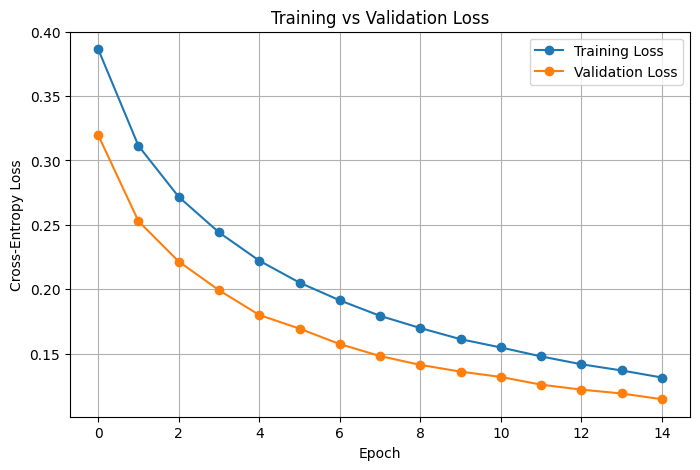

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

### 9. Evaluasi pada Data Testing

Setelah pelatihan selesai, model dievaluasi menggunakan data testing yang tidak digunakan dalam proses pembaruan bobot maupun pemilihan model terbaik.

Akurasi menunjukkan proporsi gambar yang diklasifikasikan dengan benar. Nilai akurasi yang lebih tinggi menunjukkan lebih banyak prediksi yang sesuai dengan label sebenarnya, tetapi hasil ini tetap perlu ditafsirkan sesuai kebutuhan dan karakteristik masalah.

Evaluasi pada data testing memberikan gambaran yang lebih objektif mengenai kemampuan model dalam memprediksi data baru dibandingkan hanya melihat performa pada data pelatihan.

In [9]:
test_probs, _ = forward(
    X_test, W1, b1, W2, b2,
    training=False
)

y_pred = np.argmax(test_probs, axis=1)
y_true = np.argmax(y_test_onehot, axis=1)

accuracy = np.mean(y_pred == y_true)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 0.9596
Test Accuracy: 95.96%


### 10. Visualisasi Hasil Prediksi

Kita menampilkan beberapa contoh gambar dari data testing beserta label sebenarnya dan prediksi model. Visualisasi ini membantu memeriksa apakah model berhasil mengenali angka tulisan tangan.

Perlu diperhatikan bahwa akurasi keseluruhan tidak berarti semua gambar akan diprediksi dengan benar. Beberapa angka mungkin sulit dibedakan karena bentuk tulisan tangan yang mirip atau kualitas gambar.

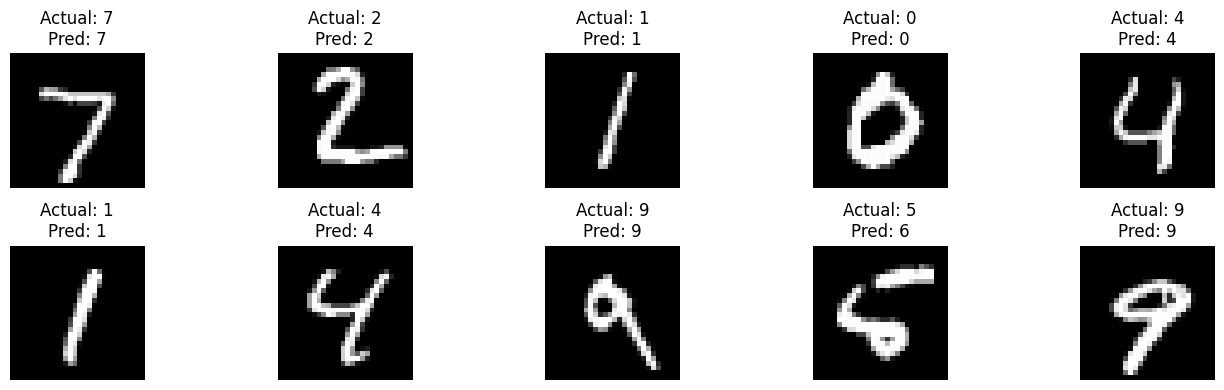

In [10]:
num_samples = 10

plt.figure(figsize=(14, 4))

for i in range(num_samples):
    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {y_true[i]}\nPred: {y_pred[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### 11. Kesimpulan

Pada notebook ini, kita membangun jaringan saraf sederhana untuk mengklasifikasikan gambar angka MNIST menggunakan NumPy. Prosesnya mencakup preprocessing data, *forward propagation*, perhitungan *cross-entropy loss*, *backpropagation*, dan pembaruan bobot.

Kita juga menerapkan *mini-batch gradient descent* untuk memperbarui parameter secara bertahap, *dropout* untuk mengurangi ketergantungan berlebihan antarneuron, serta *early stopping* untuk menghentikan pelatihan ketika performa validasi tidak lagi membaik.

Eksperimen ini memperlihatkan pentingnya membedakan performa pada data pelatihan, validasi, dan pengujian. Ketiga bagian tersebut memiliki fungsi berbeda dalam membangun dan mengevaluasi model pembelajaran mesin.